# Electricity Generation by Energy Source: Analysis and Visualization
EDAV (22ADC31N) Course-End Project

Reconstructed notebook following the report's structure (Table B.1). Place `electricity_generation_world.csv` and `electricity_generation_regions_2025.csv` in the same folder, then choose **Kernel → Restart and Run All**.

> Values are rounded approximations compiled for this academic exercise (Report Section 4.1). Replace them with the official Ember data for research use.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'font.family': 'serif', 'font.size': 11,
                     'font.serif': ['Liberation Serif', 'Times New Roman', 'DejaVu Serif']})
pd.set_option('display.width', 96)

world = pd.read_csv('electricity_generation_world.csv')
regions = pd.read_csv('electricity_generation_regions_2025.csv')

SOURCES = ['Coal', 'Gas', 'Oil', 'Nuclear', 'Hydro', 'Wind', 'Solar', 'Bioenergy', 'Other_Renewables']
CATEGORY = {'Coal': 'Fossil', 'Gas': 'Fossil', 'Oil': 'Fossil', 'Nuclear': 'Nuclear',
            'Hydro': 'Renewable', 'Wind': 'Renewable', 'Solar': 'Renewable',
            'Bioenergy': 'Renewable', 'Other_Renewables': 'Renewable'}
COLORS = {'Coal': '#4d4d4d', 'Gas': '#d98c3f', 'Oil': '#8c5a3c', 'Nuclear': '#7b5ea7',
          'Hydro': '#2f6fb3', 'Wind': '#3aa6a0', 'Solar': '#e8b923', 'Bioenergy': '#5a9e45',
          'Other_Renewables': '#a8cf8e'}

print('World dataset:', world.shape)
print('Regions dataset:', regions.shape)

World dataset: (26, 11)
Regions dataset: (5, 11)


**Q1**

                    Mean     Min      Max     Std  Peak_year  Low_year  CAGR_%
Coal              8710.2  5990.0  10540.0  1408.8       2024      2000     2.3
Gas               4991.2  2750.0   6750.0  1280.4       2025      2000     3.7
Oil               1041.5   850.0   1230.0   115.2       2003      2020    -0.8
Nuclear           2662.1  2420.0   2825.0   108.0       2025      2012     0.3
Hydro             3626.2  2620.0   4420.0   639.5       2024      2001     2.0
Wind               865.2    31.0   2700.0   848.1       2025      2000    19.6
Solar              488.3     1.0   2778.0   740.1       2025      2000    37.3
Bioenergy          412.7   160.0    690.0   191.1       2023      2000     6.0
Other_Renewables    96.2    55.0    170.0    33.8       2025      2000     4.6

Low-carbon share: 35.6 % (2000) -> 42.7 % (2025)
Linear trend of low-carbon share: +0.29 percentage points per year
Correlation (year, low-carbon share): 0.723
First year renewables > coal : 2025
Renewables > 

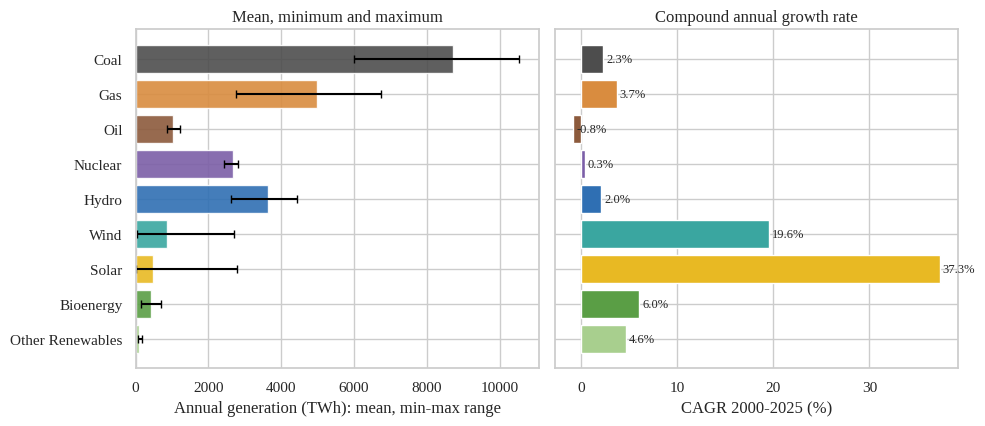

In [11]:
years = world['Year'].to_numpy()
data = world[SOURCES].to_numpy(dtype=float)	# shape: (26 years, 9 sources) print('Array shape (years x sources):', data.shape)

mean_, min_, max_ = data.mean(axis=0), data.min(axis=0), data.max(axis=0)
std_ = data.std(axis=0, ddof=1)
n_years = years[-1] - years[0]
cagr_ = ((data[-1] / data[0]) ** (1 / n_years) - 1) * 100

stats = pd.DataFrame({'Mean': mean_, 'Min': min_, 'Max': max_, 'Std': std_, 'Peak_year': years[data.argmax(axis=0)],
'Low_year': years[data.argmin(axis=0)], 'CAGR_%': cagr_}, index=SOURCES).round(1)
print(stats.to_string())

# fossil versus low-carbon totals (NumPy slicing: columns 0-2 are fossil, 3-8 low-carbon) fossil = data[:, :3].sum(axis=1)
low_carbon = data[:, 3:].sum(axis=1)
renew = data[:, 4:].sum(axis=1)
total_ = data.sum(axis=1)
slope = np.polyfit(years, 100 * low_carbon / total_, 1)[0]
print()
print('Low-carbon share: %.1f %% (2000) -> %.1f %% (2025)'
% (100 * low_carbon[0] / total_[0], 100 * low_carbon[-1] / total_[-1]))
print('Linear trend of low-carbon share: %+.2f percentage points per year' % slope)
print('Correlation (year, low-carbon share): %.3f'
% np.corrcoef(years, low_carbon / total_)[0, 1])
coal = data[:, 0]
print('First year renewables > coal :', years[np.argmax(renew > coal)])
gas = data[:, 1]
beat = renew > gas
print('Renewables > gas in every year from', years[np.where(~beat)[0].max() + 1], 'onwards')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
y = np.arange(len(SOURCES))
axes[0].barh(y, mean_, color=[COLORS[s] for s in SOURCES], alpha=0.9)
axes[0].errorbar(mean_, y, xerr=[mean_ - min_, max_ - mean_], fmt='none',
ecolor='black', capsize=3)
axes[0].set_yticks(y); axes[0].set_yticklabels([s.replace('_', ' ') for s in SOURCES])
axes[0].set_xlabel('Annual generation (TWh): mean, min-max range')
axes[0].invert_yaxis()
axes[0].set_title('Mean, minimum and maximum')
axes[1].barh(y, cagr_, color=[COLORS[s] for s in SOURCES])
axes[1].set_yticks(y); axes[1].set_yticklabels([]); axes[1].invert_yaxis()
for i, v in enumerate(cagr_):
  axes[1].text(v + 0.3, i, '%.1f%%' % v, va='center', fontsize=9)
axes[1].set_xlabel('CAGR 2000-2025 (%)'); axes[1].set_title('Compound annual growth rate')
plt.tight_layout(); plt.show()

## 2. Data collection
Structure, data types and summary statistics of the two files.

In [2]:
world.info()
print()
print(world.head(3).to_string())
print(world.tail(3).to_string())
print()
print(world[SOURCES].describe().round(0).to_string())
print()
print(regions.to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Entity            26 non-null     object
 1   Year              26 non-null     int64 
 2   Coal              26 non-null     int64 
 3   Gas               26 non-null     int64 
 4   Oil               26 non-null     int64 
 5   Nuclear           26 non-null     int64 
 6   Hydro             26 non-null     int64 
 7   Wind              26 non-null     int64 
 8   Solar             26 non-null     int64 
 9   Bioenergy         26 non-null     int64 
 10  Other_Renewables  26 non-null     int64 
dtypes: int64(10), object(1)
memory usage: 2.4+ KB

  Entity  Year  Coal   Gas   Oil  Nuclear  Hydro  Wind  Solar  Bioenergy  Other_Renewables
0  World  2000  5990  2750  1200     2590   2650    31      1        160                55
1  World  2001  6130  2850  1170     2650   2620    38      2    

**Q2**

/tmp/ipykernel_1260/3985505418.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  yearly_cat.groupby(['Period', 'Category'])['TWh']
/tmp/ipykernel_1260/3985505418.py:22: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  tot_p = yearly_cat.pivot_table(


                      mean      min      max
Period  Category                            
2000-04 Fossil     10706.0   9940.0  11710.0
        Nuclear     2640.0   2590.0   2700.0
        Renewable   2972.0   2881.0   3170.0
2005-09 Fossil     13200.0  12310.0  13780.0
        Nuclear     2716.0   2680.0   2750.0
        Renewable   3667.0   3383.0   4007.0
2010-14 Fossil     15278.0  14560.0  15770.0
        Nuclear     2538.0   2420.0   2760.0
        Renewable   4798.0   4285.0   5367.0
2015-19 Fossil     16284.0  15710.0  16820.0
        Nuclear     2648.0   2520.0   2790.0
        Renewable   6344.0   5596.0   7090.0
2020-25 Fossil     17663.0  16360.0  18200.0
        Nuclear     2751.0   2680.0   2825.0
        Renewable   8966.0   7535.0  10730.0

Category share of generation (%) by period:
Category  Fossil  Nuclear  Renewable
Period                              
2000-04     65.6     16.2       18.2
2005-09     67.4     13.9       18.7
2010-14     67.6     11.2       21.2
2015-

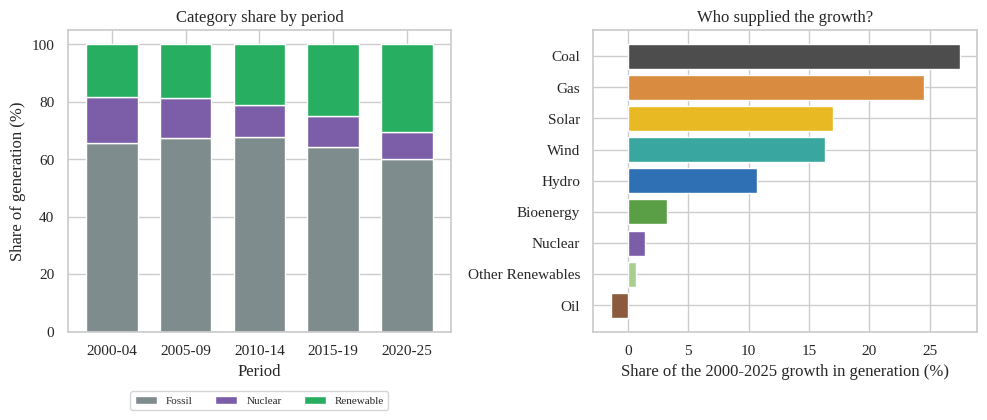

In [12]:
bins = [1999, 2004, 2009, 2014, 2019, 2025]
labels = ['2000-04', '2005-09', '2010-14', '2015-19', '2020-25']

# (a) Category totals per year, then aggregated by five-year period
yearly_cat = long.groupby(
    ['Year', 'Category'], as_index=False
)['TWh'].sum()

yearly_cat['Period'] = pd.cut(
    yearly_cat['Year'], bins=bins, labels=labels
)

cat_period = (
    yearly_cat.groupby(['Period', 'Category'])['TWh']
    .agg(['mean', 'min', 'max'])
    .round(0)
)

print(cat_period.to_string())

# (b) Share of each category within each period
tot_p = yearly_cat.pivot_table(
    index='Period',
    columns='Category',
    values='TWh',
    aggfunc='sum'
)

share_p = (
    tot_p.div(tot_p.sum(axis=1), axis=0)
    .mul(100)
    .round(1)
)

print()
print('Category share of generation (%) by period:')
print(share_p.to_string())

# (c) Contribution of each source to growth in generation, 2000–2025
delta = world.loc[25, SOURCES] - world.loc[0, SOURCES]

contrib = (
    delta / delta.sum() * 100
).sort_values(ascending=False).round(1)

print()
print('Growth in total generation 2000-2025: %.0f TWh' % delta.sum())
print('Contribution of each source to that growth (%):')
print(contrib.to_string())

# (d) Rank of each source in 2000 and 2025
rank = pd.DataFrame({
    'Rank_2000': world.loc[0, SOURCES].rank(
        ascending=False
    ).astype(int),
    'Rank_2025': world.loc[25, SOURCES].rank(
        ascending=False
    ).astype(int)
})

print()
print(rank.sort_values('Rank_2025').to_string())

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))

share_p[['Fossil', 'Nuclear', 'Renewable']].plot(
    kind='bar',
    stacked=True,
    ax=axes[0],
    color=['#7f8c8d', '#7b5ea7', '#27ae60'],
    rot=0,
    width=0.7
)

axes[0].set_ylabel('Share of generation (%)')
axes[0].set_xlabel('Period')
axes[0].set_title('Category share by period')

axes[0].legend(
    fontsize=8,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.18),
    ncol=3
)

axes[1].barh(
    [s.replace('_', ' ') for s in contrib.index],
    contrib.values,
    color=[COLORS[s] for s in contrib.index]
)

axes[1].invert_yaxis()
axes[1].set_xlabel(
    'Share of the 2000-2025 growth in generation (%)'
)
axes[1].set_title('Who supplied the growth?')

plt.tight_layout()
plt.show()

**Q3**

Missing cells in the cleaned world data: 0
Missing cells in the cleaned region data: 0
Cells hidden: 13 of 234 (5.6 %)

                      MAE_TWh  WAPE_%  Missing_after
Method                                              
Mean                    654.2   21.32              0
Median                  621.1   20.24              0
Forward fill            121.0    3.94              0
Linear interpolation     29.2    0.95              0
Best method: Linear interpolation
Placeholder demo: ['Fossil', 'Unknown', 'Renewable']
Missing values remaining after imputation: 0


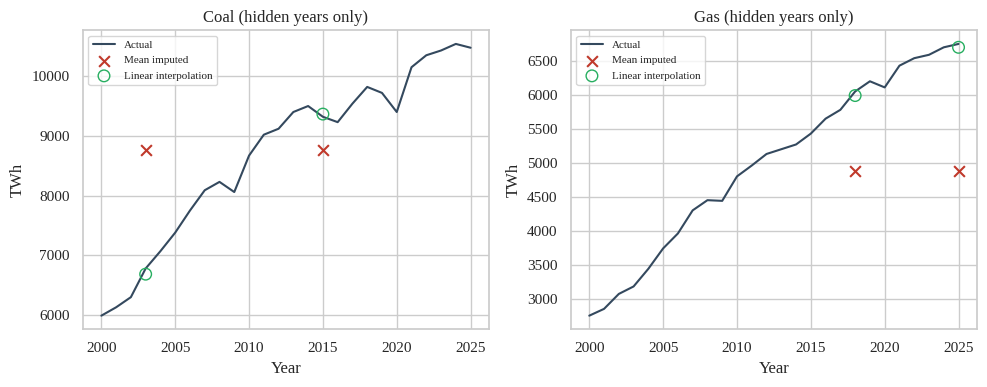

In [13]:
print(
    'Missing cells in the cleaned world data:',
    int(world[SOURCES].isna().sum().sum())
)

print(
    'Missing cells in the cleaned region data:',
    int(regions[SOURCES].isna().sum().sum())
)

rng = np.random.default_rng(42)

mask = pd.DataFrame(
    rng.random(world[SOURCES].shape) < 0.08,
    columns=SOURCES,
    index=world.index
)

masked = world[SOURCES].mask(mask)

print(
    'Cells hidden: %d of %d (%.1f %%)'
    % (
        mask.sum().sum(),
        mask.size,
        100 * mask.mean().mean()
    )
)

# Imputation methods
methods = {
    'Mean': masked.fillna(masked.mean()),
    'Median': masked.fillna(masked.median()),
    'Forward fill': masked.ffill().bfill(),
    'Linear interpolation': masked.interpolate(
        method='linear',
        limit_direction='both'
    )
}

# Actual values at the hidden cells
true_vals = world[SOURCES].to_numpy()[mask.to_numpy()]

rows = []

# Evaluate each imputation method
for name, filled in methods.items():
    est = filled.to_numpy()[mask.to_numpy()]

    mae = np.abs(est - true_vals).mean()

    wape = (
        np.abs(est - true_vals).sum()
        / np.abs(true_vals).sum()
        * 100
    )

    rows.append({
        'Method': name,
        'MAE_TWh': round(mae, 1),
        'WAPE_%': round(wape, 2),
        'Missing_after': int(filled.isna().sum().sum())
    })

result = pd.DataFrame(rows).set_index('Method')

print()
print(result.to_string())

best = result['WAPE_%'].idxmin()
print('Best method:', best)

# Categorical placeholder: unmapped labels receive 'Unknown'
test_labels = pd.Series(['Coal', 'Geothermal', 'Solar'])

print(
    'Placeholder demo:',
    test_labels.map(CATEGORY).fillna('Unknown').tolist()
)

# Final cleaned data using the best method
clean_final = methods[best]

assert clean_final.isna().sum().sum() == 0

print(
    'Missing values remaining after imputation:',
    int(clean_final.isna().sum().sum())
)

# Plot actual and imputed values for the two most-masked sources
cols = mask.sum().sort_values(ascending=False).index[:2]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, c in zip(axes, cols):
    m = mask[c]

    ax.plot(
        world['Year'],
        world[c],
        color='#34495e',
        lw=1.5,
        label='Actual'
    )

    ax.scatter(
        world.loc[m, 'Year'],
        methods['Mean'].loc[m, c],
        marker='x',
        color='#c0392b',
        s=60,
        label='Mean imputed',
        zorder=3
    )

    ax.scatter(
        world.loc[m, 'Year'],
        methods['Linear interpolation'].loc[m, c],
        marker='o',
        facecolor='none',
        edgecolor='#27ae60',
        s=70,
        zorder=3,
        label='Linear interpolation'
    )

    ax.set_title(c.replace('_', ' ') + ' (hidden years only)')
    ax.set_xlabel('Year')
    ax.set_ylabel('TWh')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Q4**

                          Total_TWh  Sources  Mean_TWh  Max_TWh  Share_%
Region         Category                                                 
China          Fossil        6090.0        3    2030.0   5750.0     57.9
               Nuclear        483.0        1     483.0    483.0      4.6
               Renewable     3940.0        5     788.0   1400.0     37.5
European Union Fossil         809.0        3     269.7    467.0     29.0
               Nuclear        654.0        1     654.0    654.0     23.4
               Renewable     1331.0        5     266.2    472.0     47.6
India          Fossil        1518.0        3     506.0   1475.0     73.0
               Nuclear         56.0        1      56.0     56.0      2.7
               Renewable      506.0        5     101.2    196.0     24.3
Rest of World  Fossil        7209.0        3    2403.0   4125.0     60.9
               Nuclear        852.0        1     852.0    852.0      7.2
               Renewable     3781.0        5     75

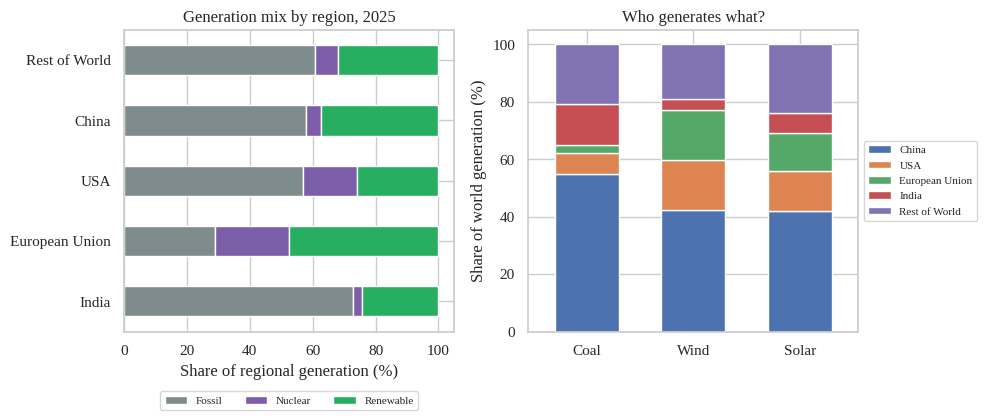

In [14]:
# Convert regional data into long format
reg_long = regions.melt(
    id_vars=['Region', 'Year'],
    value_vars=SOURCES,
    var_name='Source',
    value_name='TWh'
)

reg_long['Category'] = reg_long['Source'].map(CATEGORY)

# Aggregate generation by region and category
g = reg_long.groupby(['Region', 'Category']).agg(
    Total_TWh=('TWh', 'sum'),
    Sources=('Source', 'count'),
    Mean_TWh=('TWh', 'mean'),
    Max_TWh=('TWh', 'max')
).round(1)

region_total = g.groupby('Region')['Total_TWh'].transform('sum')
g['Share_%'] = (g['Total_TWh'] / region_total * 100).round(1)

print(g.to_string())

# Regional generation totals and source shares
rw = regions.set_index('Region')[SOURCES]
tot = rw.sum(axis=1)

mix = reg_long.pivot_table(
    index='Region',
    columns='Category',
    values='TWh',
    aggfunc='sum'
)

summary = pd.DataFrame({
    'Total_TWh': tot,
    'Coal_%': rw['Coal'] / tot * 100,
    'WindSolar_%': (rw['Wind'] + rw['Solar']) / tot * 100,
    'LowCarbon_%': (mix['Nuclear'] + mix['Renewable']) / tot * 100
}).round(1)

print()
print(summary.sort_values('Coal_%', ascending=False).to_string())

print()
print('Descriptive statistics across the five regions:')
print(
    summary.drop(columns='Total_TWh')
    .describe()
    .round(1)
    .to_string()
)

# Share of world generation by region and source
conc = rw.div(rw.sum(axis=0), axis=1) * 100

print()
print('Share of world generation by region and source (%):')
print(
    conc[['Coal', 'Gas', 'Nuclear', 'Hydro', 'Wind', 'Solar']]
    .round(1)
    .to_string()
)

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))

# Left plot: Generation mix by region
cat_share = mix.div(mix.sum(axis=1), axis=0) * 100

cat_share = cat_share.loc[
    tot.sort_values().index,
    ['Fossil', 'Nuclear', 'Renewable']
]

cat_share.plot(
    kind='barh',
    stacked=True,
    ax=axes[0],
    color=['#7f8c8d', '#7b5ea7', '#27ae60']
)

axes[0].set_xlabel('Share of regional generation (%)')
axes[0].set_ylabel('')
axes[0].set_title('Generation mix by region, 2025')

axes[0].legend(
    fontsize=8,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.18),
    ncol=3
)

# Right plot: Regional contribution by source
conc.loc[:, ['Coal', 'Wind', 'Solar']].T.plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    rot=0,
    width=0.6
)

axes[1].set_ylabel('Share of world generation (%)')
axes[1].set_xlabel('')
axes[1].set_title('Who generates what?')

axes[1].legend(
    fontsize=8,
    loc='center left',
    bbox_to_anchor=(1.0, 0.5)
)

plt.tight_layout()
plt.show()

**Q5**

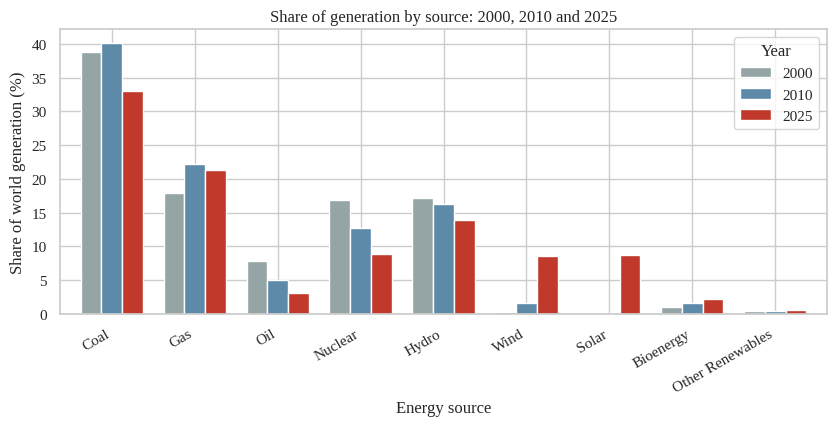

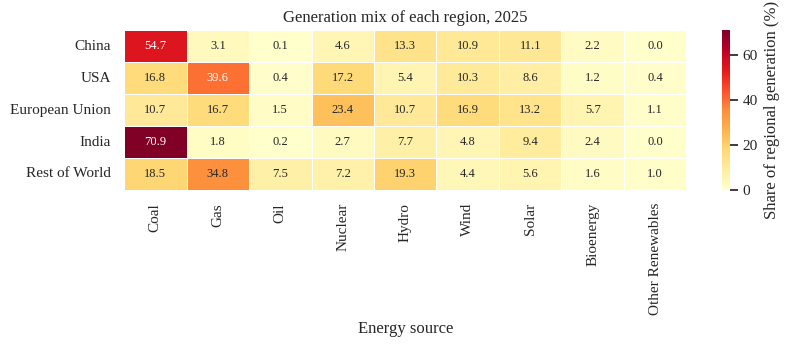

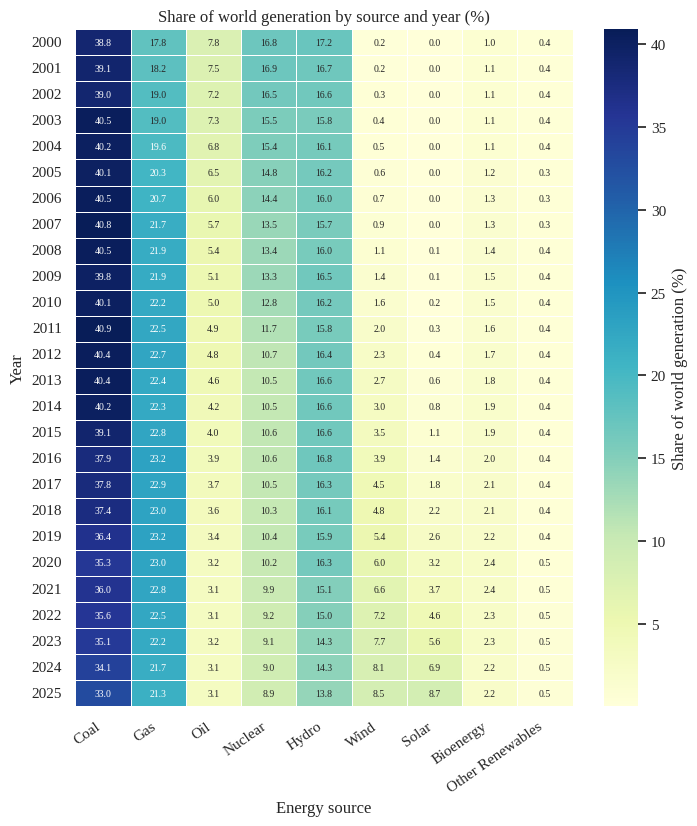

Largest share in 2000: Coal (38.8 %)
Largest share in 2025: Coal (33.0 %)
Fastest rising share: Solar (+8.7 pp)
Fastest falling share: Nuclear (-7.9 pp)


In [15]:
# (1) Grouped bar plot: share of generation by source in selected years
sel = share.set_index('Year').loc[[2000, 2010, 2025], SOURCES].T
sel.index = [s.replace('_', ' ') for s in sel.index]

ax = sel.plot(
    kind='bar',
    figsize=(8.5, 4.4),
    width=0.75,
    color=['#95a5a6', '#5d8aa8', '#c0392b']
)

ax.set_ylabel('Share of world generation (%)')
ax.set_xlabel('Energy source')
ax.set_title('Share of generation by source: 2000, 2010 and 2025')

plt.xticks(rotation=30, ha='right')
ax.legend(title='Year')
plt.tight_layout()
plt.show()


# (2) Heatmap: regional generation mix in 2025
# Percentage of each region's electricity
reg_share = rw.div(rw.sum(axis=1), axis=0) * 100
reg_share.columns = [c.replace('_', ' ') for c in reg_share.columns]

fig, ax = plt.subplots(figsize=(8.5, 3.6))

sns.heatmap(
    reg_share,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Share of regional generation (%)'},
    annot_kws={'size': 9}
)

ax.set_title('Generation mix of each region, 2025')
ax.set_xlabel('Energy source')
ax.set_ylabel('')

plt.tight_layout()
plt.show()


# (3) Heatmap: share of each source in each year
hm = share.set_index('Year')[SOURCES]
hm.columns = [c.replace('_', ' ') for c in hm.columns]

fig, ax = plt.subplots(figsize=(7.2, 8.4))

sns.heatmap(
    hm,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.4,
    annot_kws={'size': 7},
    cbar_kws={'label': 'Share of world generation (%)'},
    ax=ax
)

ax.set_title('Share of world generation by source and year (%)')
ax.set_xlabel('Energy source')
ax.set_ylabel('Year')

plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()


# Print key findings
print(
    'Largest share in 2000: %s (%.1f %%)'
    % (hm.loc[2000].idxmax(), hm.loc[2000].max())
)

print(
    'Largest share in 2025: %s (%.1f %%)'
    % (hm.loc[2025].idxmax(), hm.loc[2025].max())
)

diff = hm.loc[2025] - hm.loc[2000]

print(
    'Fastest rising share: %s (%+.1f pp)'
    % (diff.idxmax(), diff.max())
)

print(
    'Fastest falling share: %s (%+.1f pp)'
    % (diff.idxmin(), diff.min())
)

## 3. Data cleaning and preparation

In [16]:
# 3.1 Validation checks (Table 5.1)
checks = {
    'Missing values (world)': int(world.isna().sum().sum()),
    'Missing values (regions)': int(regions.isna().sum().sum()),
    'Duplicate rows (world)': int(world.duplicated().sum()),
    'Duplicate rows (regions)': int(regions.duplicated().sum()),
    'Duplicate years': int(world['Year'].duplicated().sum()),
    'Negative values': int((world[SOURCES] < 0).sum().sum() + (regions[SOURCES] < 0).sum().sum()),
    'Year continuity (no gaps)': bool((world['Year'].diff().dropna() == 1).all()),
}
for k, v in checks.items():
    print(f'{k:28s}: {v}')

# convert to float64
world[SOURCES] = world[SOURCES].astype(float)
regions[SOURCES] = regions[SOURCES].astype(float)

Missing values (world)      : 0
Missing values (regions)    : 0
Duplicate rows (world)      : 0
Duplicate rows (regions)    : 0
Duplicate years             : 0
Negative values             : 0
Year continuity (no gaps)   : True


In [17]:
# 3.2 Engineered features (Table 5.3)
world['Total'] = world[SOURCES].sum(axis=1)
world['Fossil'] = world[['Coal', 'Gas', 'Oil']].sum(axis=1)
world['Renewable'] = world[['Hydro', 'Wind', 'Solar', 'Bioenergy', 'Other_Renewables']].sum(axis=1)
world['Low_Carbon'] = world['Renewable'] + world['Nuclear']

# percentage share of each source (columns keep the source names)
share = world[['Year']].copy()
for s in SOURCES:
    share[s] = 100 * world[s] / world['Total']
assert np.allclose(share[SOURCES].sum(axis=1), 100)

# tidy (long) format: 26 years x 9 sources = 234 observations
long = world.melt(id_vars='Year', value_vars=SOURCES, var_name='Source', value_name='TWh')
long['Category'] = long['Source'].map(CATEGORY).fillna('Unknown')
assert (long['Category'] != 'Unknown').all() and len(long) == 234

# Period (five-year bins) used in Q2
bins = [1999, 2004, 2009, 2014, 2019, 2025]
labels = ['2000-04', '2005-09', '2010-14', '2015-19', '2020-25']
long['Period'] = pd.cut(long['Year'], bins=bins, labels=labels)
print(world[['Year', 'Total', 'Fossil', 'Renewable', 'Low_Carbon']].tail(3).to_string())
print('Tidy rows:', len(long))

    Year    Total   Fossil  Renewable  Low_Carbon
23  2023  29730.0  17960.0     9050.0     11770.0
24  2024  30877.0  18200.0     9887.0     12677.0
25  2025  31751.0  18196.0    10730.0     13555.0
Tidy rows: 234


                  Median    Max  Min  IQR_outliers
Coal                 2.3    8.0 -3.3             0
Gas                  3.4    8.7 -1.5             0
Oil                 -1.7    5.8 -6.5             0
Nuclear              1.3    3.8 -6.5             1
Hydro                2.3    7.2 -2.7             0
Wind                20.5   39.5  8.2             0
Solar               33.3  100.0  0.0             2
Bioenergy            6.1   15.8 -1.4             2
Other_Renewables     4.3   13.3  0.0             4


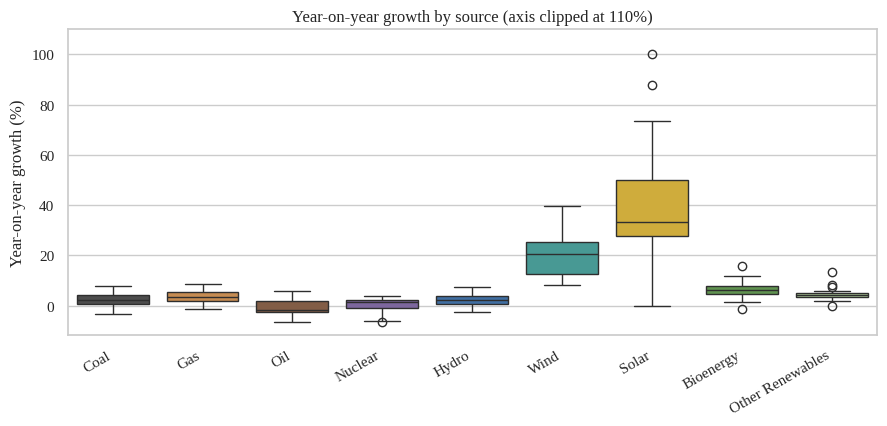

In [18]:
# 3.3 Outlier detection: 1.5 x IQR rule on year-on-year growth (Table 5.2, Fig. 5.1)
growth = world[SOURCES].pct_change().iloc[1:] * 100
q1, q3 = growth.quantile(0.25), growth.quantile(0.75)
iqr = q3 - q1
flag = (growth < q1 - 1.5 * iqr) | (growth > q3 + 1.5 * iqr)
t52 = pd.DataFrame({'Median': growth.median(), 'Max': growth.max(),
                    'Min': growth.min(), 'IQR_outliers': flag.sum()}).round(1)
print(t52.to_string())

fig, ax = plt.subplots(figsize=(9, 4.4))
sns.boxplot(data=growth.rename(columns=lambda c: c.replace('_', ' ')), ax=ax, palette=[COLORS[s] for s in SOURCES])
ax.set_ylim(top=110); ax.set_ylabel('Year-on-year growth (%)'); ax.set_title('Year-on-year growth by source (axis clipped at 110%)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

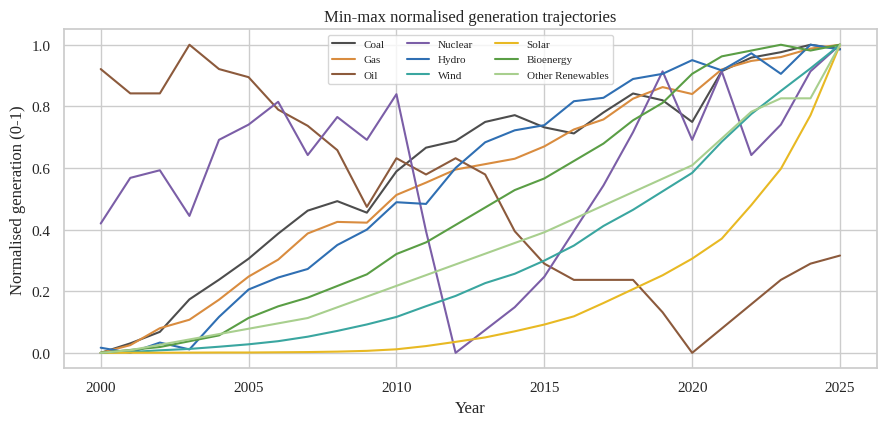

In [19]:
# 3.4 Min-max normalisation: x' = (x - min) / (max - min)  (Fig. 5.2)
norm = (world[SOURCES] - world[SOURCES].min()) / (world[SOURCES].max() - world[SOURCES].min())
fig, ax = plt.subplots(figsize=(9, 4.4))
for s in SOURCES:
    ax.plot(world['Year'], norm[s], label=s.replace('_', ' '), color=COLORS[s])
ax.set_xlabel('Year'); ax.set_ylabel('Normalised generation (0-1)')
ax.set_title('Min-max normalised generation trajectories'); ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

## 4. Exploratory data analysis

                    mean     std     min     25%     50%     75%      max
Coal              8710.0  1409.0  5990.0  7828.0  9175.0  9675.0  10540.0
Gas               4991.0  1280.0  2750.0  4045.0  5165.0  6095.0   6750.0
Oil               1042.0   115.0   850.0   940.0  1050.0  1145.0   1230.0
Nuclear           2662.0   108.0  2420.0  2592.0  2690.0  2728.0   2825.0
Hydro             3626.0   639.0  2620.0  3072.0  3775.0  4242.0   4420.0
Wind               865.0   848.0    31.0   142.0   580.0  1390.0   2700.0
Solar              488.0   740.0     1.0     6.0   120.0   669.0   2778.0
Bioenergy          413.0   191.0   160.0   244.0   395.0   582.0    690.0
Other_Renewables    96.0    34.0    55.0    66.0    90.0   119.0    170.0

Total: 15427 -> 31751 TWh, ratio 2.06, CAGR 2.93 %
Years with decline: {2009: -0.51, 2020: -0.39}


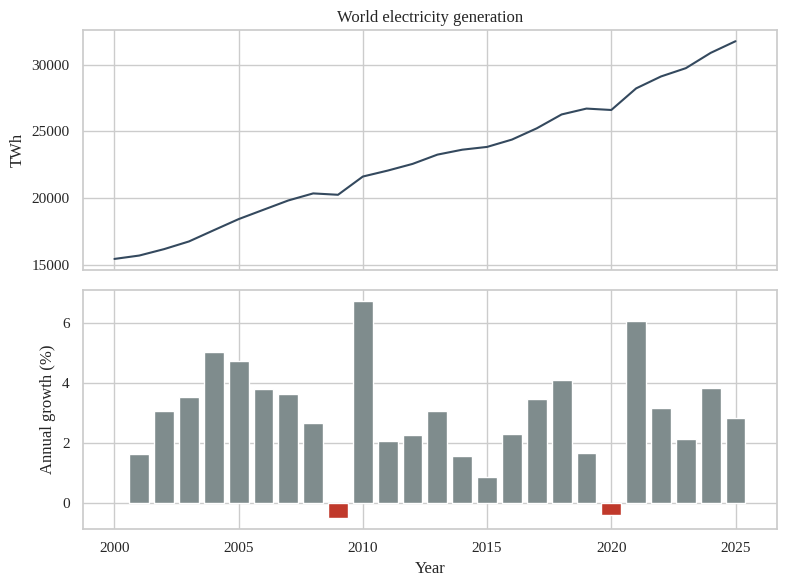

In [20]:
# 4.1 Summary statistics (Table 6.1)
print(world[SOURCES].describe().round(0).T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].to_string())

# 4.2 Trend of total generation (Fig. 6.1)
tot = world.set_index('Year')['Total']
yoy = tot.pct_change() * 100
print('\nTotal: %.0f -> %.0f TWh, ratio %.2f, CAGR %.2f %%' % (tot.iloc[0], tot.iloc[-1],
      tot.iloc[-1] / tot.iloc[0], ((tot.iloc[-1] / tot.iloc[0]) ** (1 / 25) - 1) * 100))
print('Years with decline:', {int(y): round(v, 2) for y, v in yoy[yoy < 0].items()})
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(tot.index, tot.values, color='#34495e'); axes[0].set_ylabel('TWh')
axes[0].set_title('World electricity generation')
axes[1].bar(yoy.index, yoy.values, color=np.where(yoy.values < 0, '#c0392b', '#7f8c8d'))
axes[1].set_ylabel('Annual growth (%)'); axes[1].set_xlabel('Year')
plt.tight_layout(); plt.show()

Skewness: {'Coal': -0.59, 'Gas': -0.31, 'Oil': 0.07, 'Nuclear': -0.73, 'Hydro': -0.33, 'Wind': 0.88, 'Solar': 1.87, 'Bioenergy': 0.18, 'Other_Renewables': 0.61}


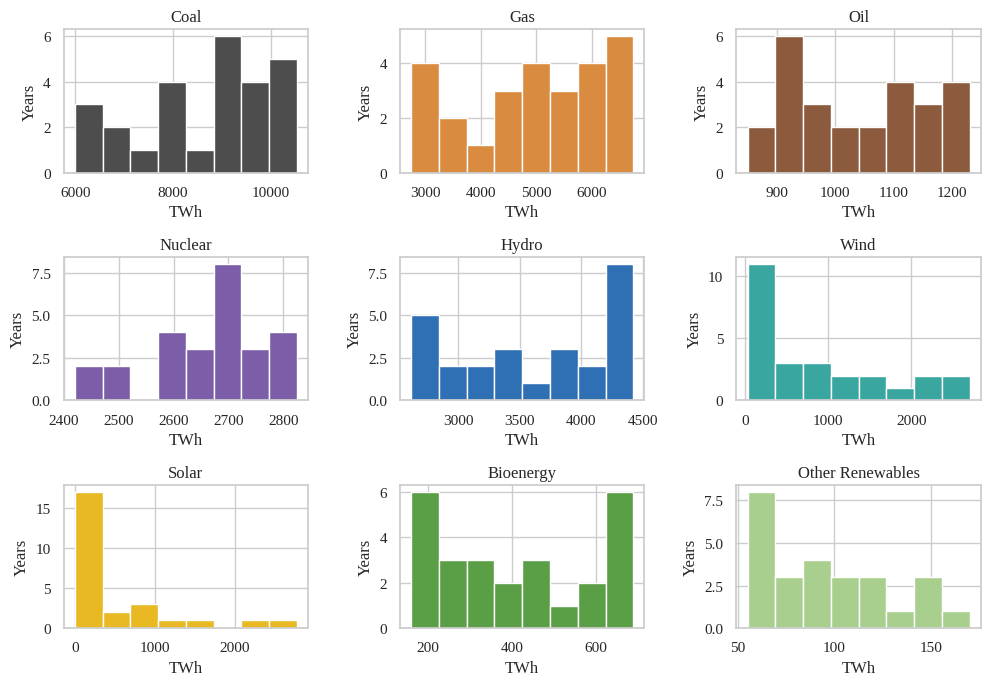

In [21]:
# 4.3 Distributions (Fig. 6.2)
print('Skewness:', world[SOURCES].skew().round(2).to_dict())
fig, axes = plt.subplots(3, 3, figsize=(10, 7))
for ax, s in zip(axes.ravel(), SOURCES):
    ax.hist(world[s], bins=8, color=COLORS[s], edgecolor='white')
    ax.set_title(s.replace('_', ' ')); ax.set_xlabel('TWh'); ax.set_ylabel('Years')
plt.tight_layout(); plt.show()

coal-total 0.96 | solar-wind 0.95
growth: coal-gas 0.66 | solar-coal 0.17


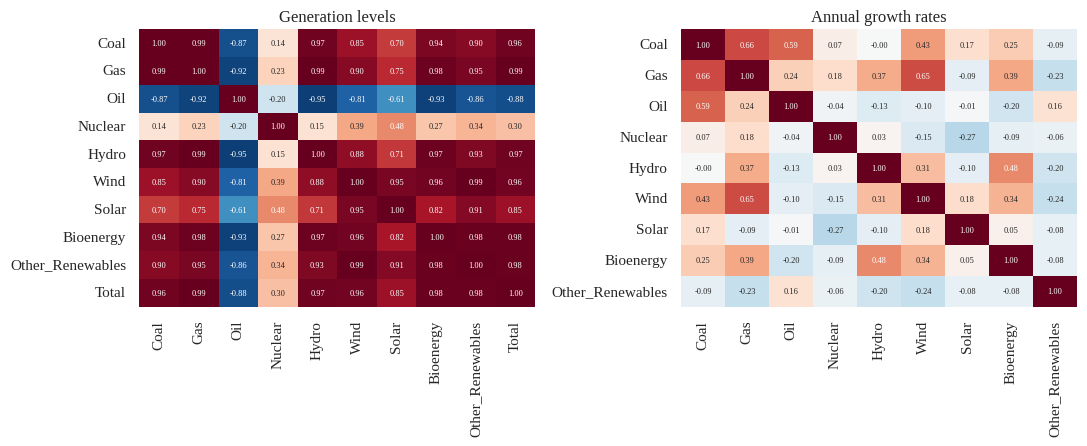

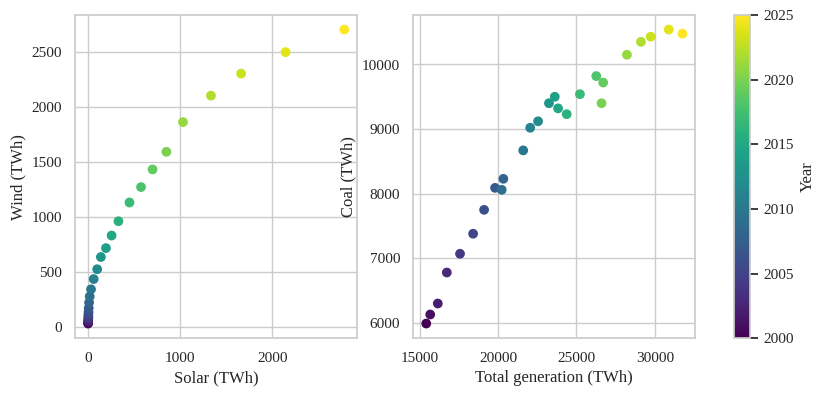

In [22]:
# 4.4 Relationships (Fig. 6.3 and 6.4)
lv = world[SOURCES + ['Total']].corr()
gr = world[SOURCES].pct_change().iloc[1:].corr()
print('coal-total %.2f | solar-wind %.2f' % (lv.loc['Coal', 'Total'], lv.loc['Solar', 'Wind']))
print('growth: coal-gas %.2f | solar-coal %.2f' % (gr.loc['Coal', 'Gas'], gr.loc['Solar', 'Coal']))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
sns.heatmap(lv, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[0], annot_kws={'size': 6}, cbar=False)
axes[0].set_title('Generation levels')
sns.heatmap(gr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[1], annot_kws={'size': 6}, cbar=False)
axes[1].set_title('Annual growth rates')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
sc = axes[0].scatter(world['Solar'], world['Wind'], c=world['Year'], cmap='viridis')
axes[0].set_xlabel('Solar (TWh)'); axes[0].set_ylabel('Wind (TWh)')
axes[1].scatter(world['Total'], world['Coal'], c=world['Year'], cmap='viridis')
axes[1].set_xlabel('Total generation (TWh)'); axes[1].set_ylabel('Coal (TWh)')
fig.colorbar(sc, ax=axes, label='Year'); plt.show()

## 5. Data visualization (Chapter 7)

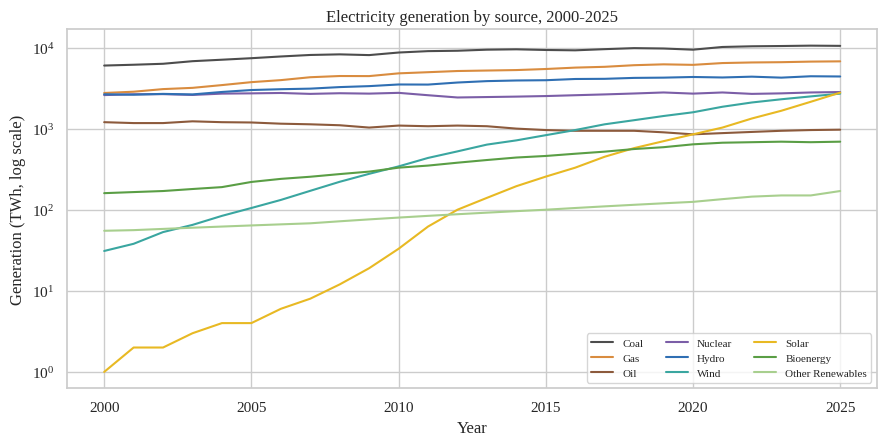

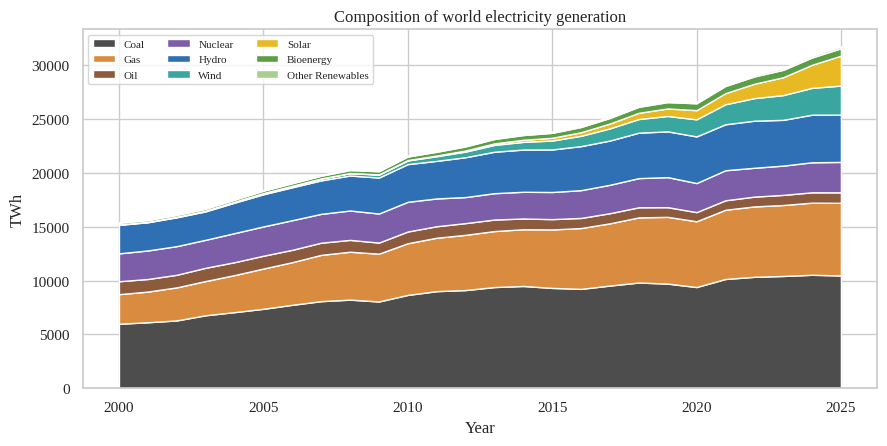

In [23]:
# 7.1 Line chart, logarithmic scale
fig, ax = plt.subplots(figsize=(9, 4.6))
for s in SOURCES:
    ax.plot(world['Year'], world[s], label=s.replace('_', ' '), color=COLORS[s])
ax.set_yscale('log'); ax.set_xlabel('Year'); ax.set_ylabel('Generation (TWh, log scale)')
ax.set_title('Electricity generation by source, 2000-2025'); ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

# 7.2 Stacked area
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.stackplot(world['Year'], [world[s] for s in SOURCES], labels=[s.replace('_', ' ') for s in SOURCES],
             colors=[COLORS[s] for s in SOURCES])
ax.set_xlabel('Year'); ax.set_ylabel('TWh'); ax.set_title('Composition of world electricity generation')
ax.legend(fontsize=8, loc='upper left', ncol=3); plt.tight_layout(); plt.show()

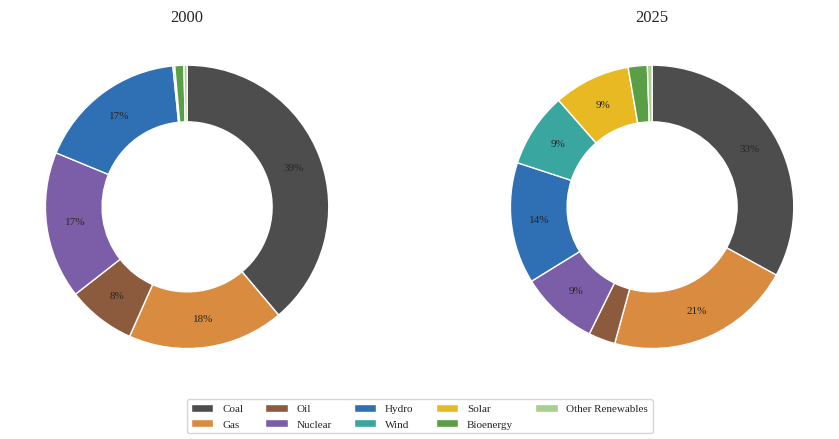

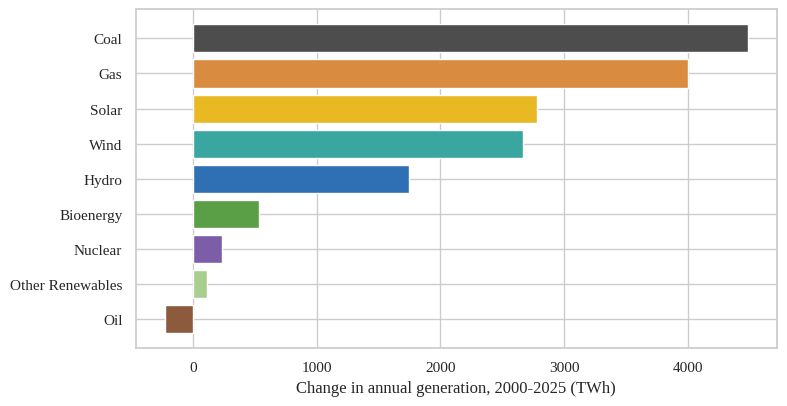

Fossil share of growth: 50.6 % | renewables: 48.0 %


In [24]:
# 7.3 Donut charts, 2000 versus 2025
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, yr in zip(axes, [2000, 2025]):
    vals = world.loc[world['Year'] == yr, SOURCES].iloc[0]
    ax.pie(vals, colors=[COLORS[s] for s in SOURCES], startangle=90, counterclock=False,
           wedgeprops=dict(width=0.4, edgecolor='white'),
           autopct=lambda p: '%.0f%%' % p if p > 4 else '', pctdistance=0.8, textprops={'fontsize': 8})
    ax.set_title(str(yr))
fig.legend(labels=[s.replace('_', ' ') for s in SOURCES], loc='lower center', ncol=5, fontsize=8)
plt.show()

# 7.4 Change in annual generation 2000 -> 2025
delta7 = (world.loc[25, SOURCES] - world.loc[0, SOURCES]).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([s.replace('_', ' ') for s in delta7.index], delta7.values, color=[COLORS[s] for s in delta7.index])
ax.invert_yaxis(); ax.set_xlabel('Change in annual generation, 2000-2025 (TWh)')
plt.tight_layout(); plt.show()
print('Fossil share of growth: %.1f %% | renewables: %.1f %%' % (
    100 * delta7[['Coal', 'Gas', 'Oil']].sum() / delta7.sum(),
    100 * delta7[['Hydro', 'Wind', 'Solar', 'Bioenergy', 'Other_Renewables']].sum() / delta7.sum()))

ValueError: s must be a scalar, or float array-like with the same size as x and y

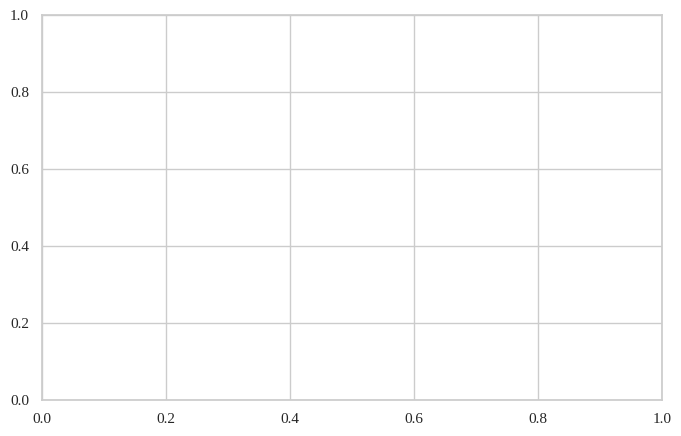

In [25]:
# 7.5 Bubble chart: CAGR versus 2025 share
cagr7 = ((world.loc[25, SOURCES] / world.loc[0, SOURCES]) ** (1 / 25) - 1) * 100
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(share.loc[25, SOURCES], cagr7, s=world.loc[25, SOURCES] / 6,
           c=[COLORS[s] for s in SOURCES], alpha=0.8, edgecolor='k')
for s in SOURCES:
    ax.annotate(s.replace('_', ' '), (share.loc[25, s], cagr7[s]), fontsize=8, xytext=(5, 5), textcoords='offset points')
ax.set_xlabel('Share of world generation, 2025 (%)'); ax.set_ylabel('CAGR 2000-2025 (%)')
ax.set_title('Growth momentum versus current share'); plt.tight_layout(); plt.show()

# 7.6 Category shares over time
cat = pd.DataFrame({'Fossil': world['Fossil'], 'Nuclear': world['Nuclear'], 'Renewable': world['Renewable']})
cat = cat.div(world['Total'], axis=0) * 100; cat.index = world['Year']
ax = cat.plot(figsize=(8, 4.2), color=['#7f8c8d', '#7b5ea7', '#27ae60'])
ax.set_ylabel('Share of world generation (%)'); ax.set_title('Share by category, 2000-2025')
plt.tight_layout(); plt.show()
print('Peak fossil share: %.1f %% in %d | 2025: %.1f %%' % (cat['Fossil'].max(), cat['Fossil'].idxmax(), cat['Fossil'].iloc[-1]))

## 6. Course questions Q1-Q5
### Q1: NumPy statistics of generation by source [CO1, BL3]

Array shape (years x sources): (26, 9)
                    Mean     Min      Max     Std  Peak_year  Low_year  CAGR_%
Coal              8710.2  5990.0  10540.0  1408.8       2024      2000     2.3
Gas               4991.2  2750.0   6750.0  1280.4       2025      2000     3.7
Oil               1041.5   850.0   1230.0   115.2       2003      2020    -0.8
Nuclear           2662.1  2420.0   2825.0   108.0       2025      2012     0.3
Hydro             3626.2  2620.0   4420.0   639.5       2024      2001     2.0
Wind               865.2    31.0   2700.0   848.1       2025      2000    19.6
Solar              488.3     1.0   2778.0   740.1       2025      2000    37.3
Bioenergy          412.7   160.0    690.0   191.1       2023      2000     6.0
Other_Renewables    96.2    55.0    170.0    33.8       2025      2000     4.6

Low-carbon share: 35.6 % (2000) -> 42.7 % (2025)
Linear trend of low-carbon share: +0.29 percentage points per year
Correlation (year, low-carbon share): 0.723
First year

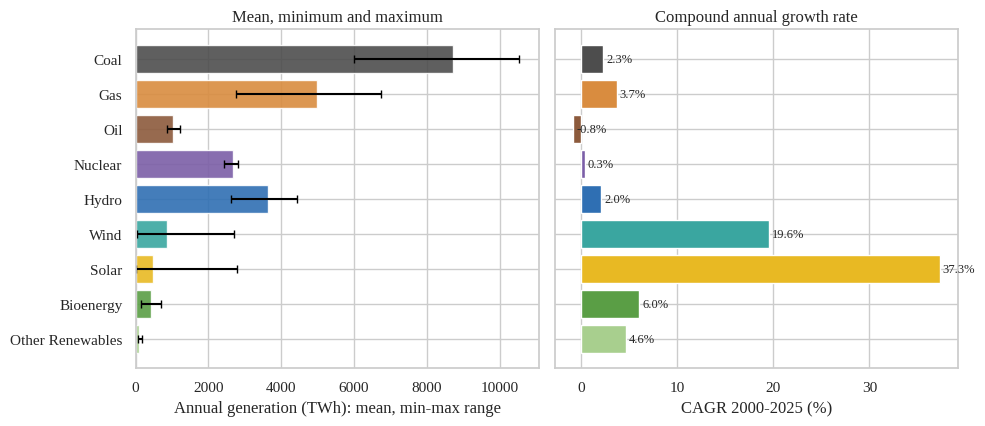

In [26]:
years = world['Year'].to_numpy()
data = world[SOURCES].to_numpy(dtype=float)   # shape: (26 years, 9 sources)
print('Array shape (years x sources):', data.shape)

mean_, min_, max_ = data.mean(axis=0), data.min(axis=0), data.max(axis=0)
std_ = data.std(axis=0, ddof=1)
n_years = years[-1] - years[0]
cagr_ = ((data[-1] / data[0]) ** (1 / n_years) - 1) * 100
stats = pd.DataFrame({'Mean': mean_, 'Min': min_, 'Max': max_, 'Std': std_,
                      'Peak_year': years[data.argmax(axis=0)],
                      'Low_year': years[data.argmin(axis=0)], 'CAGR_%': cagr_},
                     index=SOURCES).round(1)
print(stats.to_string())

# fossil versus low-carbon totals (columns 0-2 are fossil, 3-8 low-carbon)
fossil = data[:, :3].sum(axis=1)
low_carbon = data[:, 3:].sum(axis=1)
renew = data[:, 4:].sum(axis=1)
total_ = data.sum(axis=1)
slope = np.polyfit(years, 100 * low_carbon / total_, 1)[0]
print()
print('Low-carbon share: %.1f %% (2000) -> %.1f %% (2025)'
      % (100 * low_carbon[0] / total_[0], 100 * low_carbon[-1] / total_[-1]))
print('Linear trend of low-carbon share: %+.2f percentage points per year' % slope)
print('Correlation (year, low-carbon share): %.3f' % np.corrcoef(years, low_carbon / total_)[0, 1])
coal = data[:, 0]
print('First year renewables > coal :', years[np.argmax(renew > coal)])
gas = data[:, 1]
beat = renew > gas
print('Renewables > gas in every year from', years[np.where(~beat)[0].max() + 1], 'onwards')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
y = np.arange(len(SOURCES))
axes[0].barh(y, mean_, color=[COLORS[s] for s in SOURCES], alpha=0.9)
axes[0].errorbar(mean_, y, xerr=[mean_ - min_, max_ - mean_], fmt='none', ecolor='black', capsize=3)
axes[0].set_yticks(y); axes[0].set_yticklabels([s.replace('_', ' ') for s in SOURCES])
axes[0].set_xlabel('Annual generation (TWh): mean, min-max range'); axes[0].invert_yaxis()
axes[0].set_title('Mean, minimum and maximum')
axes[1].barh(y, cagr_, color=[COLORS[s] for s in SOURCES])
axes[1].set_yticks(y); axes[1].set_yticklabels([]); axes[1].invert_yaxis()
for i, v in enumerate(cagr_):
    axes[1].text(v + 0.3, i, '%.1f%%' % v, va='center', fontsize=9)
axes[1].set_xlabel('CAGR 2000-2025 (%)'); axes[1].set_title('Compound annual growth rate')
plt.tight_layout(); plt.show()

### Q2: Pandas groupby analysis of category and period [CO2, BL4]

                      mean      min      max
Period  Category                            
2000-04 Fossil     10706.0   9940.0  11710.0
        Nuclear     2640.0   2590.0   2700.0
        Renewable   2972.0   2881.0   3170.0
2005-09 Fossil     13200.0  12310.0  13780.0
        Nuclear     2716.0   2680.0   2750.0
        Renewable   3667.0   3383.0   4007.0
2010-14 Fossil     15278.0  14560.0  15770.0
        Nuclear     2538.0   2420.0   2760.0
        Renewable   4798.0   4285.0   5367.0
2015-19 Fossil     16284.0  15710.0  16820.0
        Nuclear     2648.0   2520.0   2790.0
        Renewable   6344.0   5596.0   7090.0
2020-25 Fossil     17663.0  16360.0  18200.0
        Nuclear     2751.0   2680.0   2825.0
        Renewable   8966.0   7535.0  10730.0

Category share of generation (%) by period:
Category  Fossil  Nuclear  Renewable
Period                              
2000-04     65.6     16.2       18.2
2005-09     67.4     13.9       18.7
2010-14     67.6     11.2       21.2
2015-

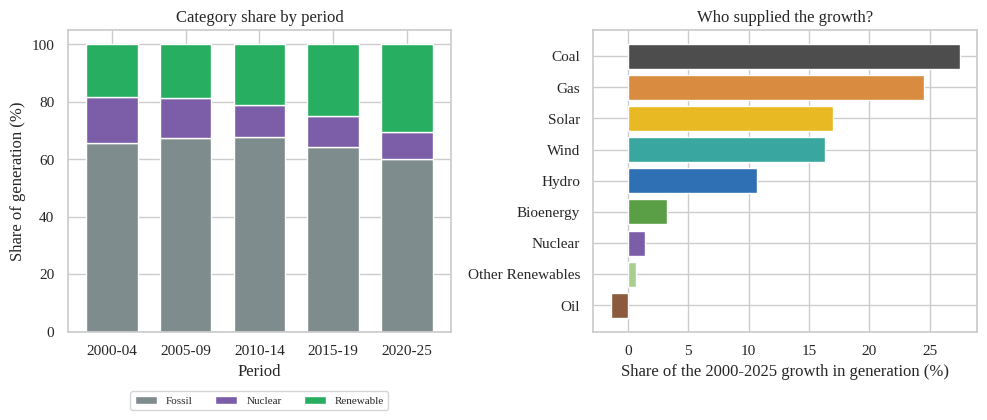

In [27]:
# (a) category totals per year, then aggregated by five-year period
yearly_cat = long.groupby(['Year', 'Category'], as_index=False)['TWh'].sum()
yearly_cat['Period'] = pd.cut(yearly_cat['Year'], bins=bins, labels=labels)
cat_period = (yearly_cat.groupby(['Period', 'Category'], observed=True)['TWh']
              .agg(['mean', 'min', 'max']).round(0))
print(cat_period.to_string())

# (b) share of each category within each period
tot_p = yearly_cat.pivot_table(index='Period', columns='Category', values='TWh',
                               aggfunc='sum', observed=True)
share_p = tot_p.div(tot_p.sum(axis=1), axis=0).mul(100).round(1)
print()
print('Category share of generation (%) by period:')
print(share_p.to_string())

# (c) contribution of each source to the growth in generation 2000 -> 2025
delta = world.loc[25, SOURCES] - world.loc[0, SOURCES]
contrib = (delta / delta.sum() * 100).sort_values(ascending=False).round(1)
print()
print('Growth in total generation 2000-2025: %.0f TWh' % delta.sum())
print('Contribution of each source to that growth (%):')
print(contrib.to_string())

# (d) rank of each source in 2000 and 2025
rank = pd.DataFrame({'Rank_2000': world.loc[0, SOURCES].rank(ascending=False).astype(int),
                     'Rank_2025': world.loc[25, SOURCES].rank(ascending=False).astype(int)})
print()
print(rank.sort_values('Rank_2025').to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
share_p[['Fossil', 'Nuclear', 'Renewable']].plot(kind='bar', stacked=True, ax=axes[0],
        color=['#7f8c8d', '#7b5ea7', '#27ae60'], rot=0, width=0.7)
axes[0].set_ylabel('Share of generation (%)'); axes[0].set_xlabel('Period')
axes[0].set_title('Category share by period')
axes[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3)
axes[1].barh([s.replace('_', ' ') for s in contrib.index], contrib.values,
             color=[COLORS[s] for s in contrib.index]); axes[1].invert_yaxis()
axes[1].set_xlabel('Share of the 2000-2025 growth in generation (%)')
axes[1].set_title('Who supplied the growth?'); plt.tight_layout(); plt.show()

### Q3: Missing-value handling and imputation [CO3, BL3]

Missing cells in the cleaned world data : 0
Missing cells in the cleaned region data: 0
Cells hidden: 13 of 234 (5.6 %)

                      MAE_TWh  WAPE_%  Missing_after
Method                                              
Mean                    654.2   21.32              0
Median                  621.1   20.24              0
Forward fill            121.0    3.94              0
Linear interpolation     29.2    0.95              0
Best method: Linear interpolation
Placeholder demo: ['Fossil', 'Unknown', 'Renewable']
Missing values remaining after imputation: 0


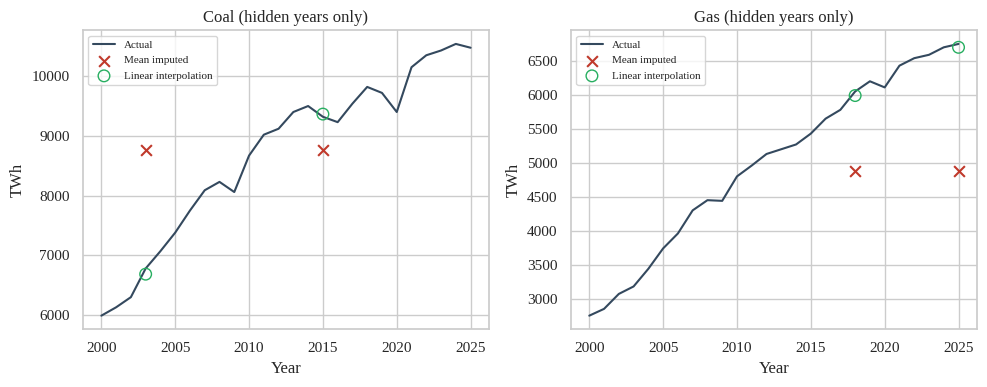

In [28]:
print('Missing cells in the cleaned world data :', int(world[SOURCES].isna().sum().sum()))
print('Missing cells in the cleaned region data:', int(regions[SOURCES].isna().sum().sum()))

rng = np.random.default_rng(42)
mask = pd.DataFrame(rng.random(world[SOURCES].shape) < 0.08, columns=SOURCES, index=world.index)
masked = world[SOURCES].mask(mask)
print('Cells hidden: %d of %d (%.1f %%)' % (mask.sum().sum(), mask.size, 100 * mask.mean().mean()))

methods = {
    'Mean': masked.fillna(masked.mean()),
    'Median': masked.fillna(masked.median()),
    'Forward fill': masked.ffill().bfill(),
    'Linear interpolation': masked.interpolate(method='linear', limit_direction='both'),
}
true_vals = world[SOURCES].to_numpy()[mask.to_numpy()]
rows = []
for name, filled in methods.items():
    est = filled.to_numpy()[mask.to_numpy()]
    mae = np.abs(est - true_vals).mean()
    wape = np.abs(est - true_vals).sum() / true_vals.sum() * 100
    rows.append({'Method': name, 'MAE_TWh': round(mae, 1), 'WAPE_%': round(wape, 2),
                 'Missing_after': int(filled.isna().sum().sum())})
result = pd.DataFrame(rows).set_index('Method')
print()
print(result.to_string())
best = result['WAPE_%'].idxmin()
print('Best method:', best)

# categorical placeholder: unmapped labels receive 'Unknown' instead of NaN
test_labels = pd.Series(['Coal', 'Geothermal', 'Solar'])
print('Placeholder demo:', test_labels.map(CATEGORY).fillna('Unknown').tolist())
clean_final = methods[best]
assert clean_final.isna().sum().sum() == 0
print('Missing values remaining after imputation:', int(clean_final.isna().sum().sum()))

cols = mask.sum().sort_values(ascending=False).index[:2]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, c in zip(axes, cols):
    m = mask[c]
    ax.plot(world['Year'], world[c], color='#34495e', lw=1.5, label='Actual')
    ax.scatter(world.loc[m, 'Year'], methods['Mean'].loc[m, c], marker='x', color='#c0392b', s=60,
               label='Mean imputed', zorder=3)
    ax.scatter(world.loc[m, 'Year'], methods['Linear interpolation'].loc[m, c], marker='o',
               facecolor='none', edgecolor='#27ae60', s=70, zorder=3, label='Linear interpolation')
    ax.set_title(c.replace('_', ' ') + ' (hidden years only)'); ax.set_xlabel('Year')
    ax.set_ylabel('TWh'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Q4: Group by region and category for descriptive statistics [CO4, BL4]

                          Total_TWh  Sources  Mean_TWh  Max_TWh  Share_%
Region         Category                                                 
China          Fossil        6090.0        3    2030.0   5750.0     57.9
               Nuclear        483.0        1     483.0    483.0      4.6
               Renewable     3940.0        5     788.0   1400.0     37.5
European Union Fossil         809.0        3     269.7    467.0     29.0
               Nuclear        654.0        1     654.0    654.0     23.4
               Renewable     1331.0        5     266.2    472.0     47.6
India          Fossil        1518.0        3     506.0   1475.0     73.0
               Nuclear         56.0        1      56.0     56.0      2.7
               Renewable      506.0        5     101.2    196.0     24.3
Rest of World  Fossil        7209.0        3    2403.0   4125.0     60.9
               Nuclear        852.0        1     852.0    852.0      7.2
               Renewable     3781.0        5     75

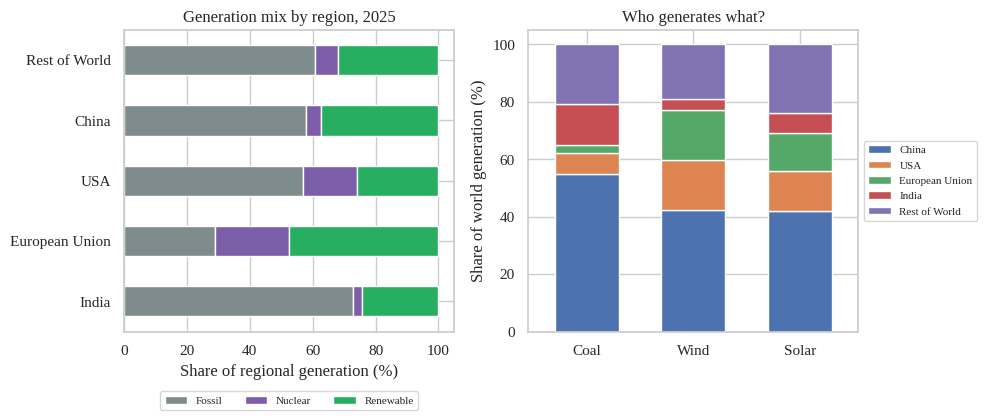

In [29]:
reg_long = regions.melt(id_vars=['Region', 'Year'], value_vars=SOURCES, var_name='Source', value_name='TWh')
reg_long['Category'] = reg_long['Source'].map(CATEGORY)
g = reg_long.groupby(['Region', 'Category']).agg(Total_TWh=('TWh', 'sum'), Sources=('Source', 'count'),
                                                 Mean_TWh=('TWh', 'mean'), Max_TWh=('TWh', 'max')).round(1)
region_total = g.groupby('Region')['Total_TWh'].transform('sum')
g['Share_%'] = (g['Total_TWh'] / region_total * 100).round(1)
print(g.to_string())

rw = regions.set_index('Region')[SOURCES]
tot = rw.sum(axis=1)
mix = reg_long.pivot_table(index='Region', columns='Category', values='TWh', aggfunc='sum')
summary = pd.DataFrame({'Total_TWh': tot,
                        'Coal_%': rw['Coal'] / tot * 100,
                        'WindSolar_%': (rw['Wind'] + rw['Solar']) / tot * 100,
                        'LowCarbon_%': (mix['Nuclear'] + mix['Renewable']) / tot * 100}).round(1)
print()
print(summary.sort_values('Coal_%', ascending=False).to_string())
print()
print('Descriptive statistics across the five regions:')
print(summary.drop(columns='Total_TWh').describe().round(1).to_string())

conc = rw.div(rw.sum(axis=0), axis=1) * 100
print()
print('Share of world generation by region and source (%):')
print(conc[['Coal', 'Gas', 'Nuclear', 'Hydro', 'Wind', 'Solar']].round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
cat_share = mix.div(mix.sum(axis=1), axis=0) * 100
cat_share = cat_share.loc[tot.sort_values().index, ['Fossil', 'Nuclear', 'Renewable']]
cat_share.plot(kind='barh', stacked=True, ax=axes[0], color=['#7f8c8d', '#7b5ea7', '#27ae60'])
axes[0].set_xlabel('Share of regional generation (%)'); axes[0].set_ylabel('')
axes[0].set_title('Generation mix by region, 2025')
axes[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3)
conc.loc[:, ['Coal', 'Wind', 'Solar']].T.plot(kind='bar', stacked=True, ax=axes[1], rot=0, width=0.6)
axes[1].set_ylabel('Share of world generation (%)'); axes[1].set_xlabel('')
axes[1].set_title('Who generates what?')
axes[1].legend(fontsize=8, loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()

### Q5: Bar plots and heat-maps of the generation mix [CO5, BL5]

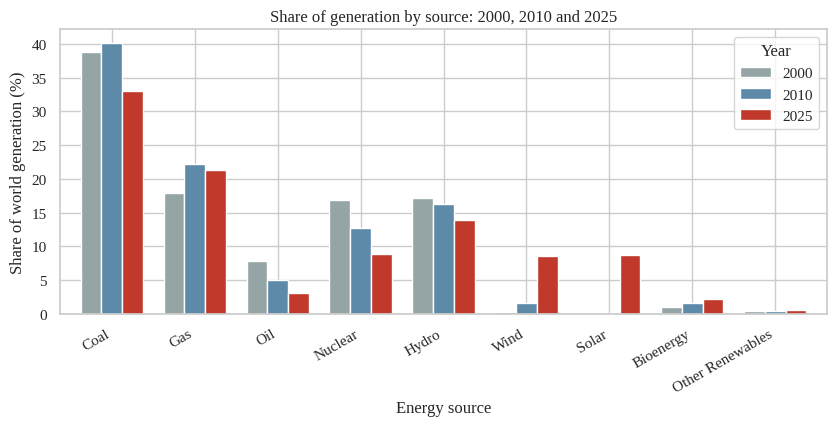

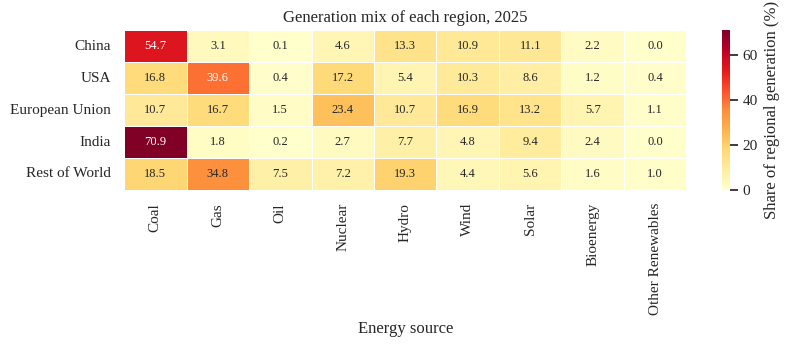

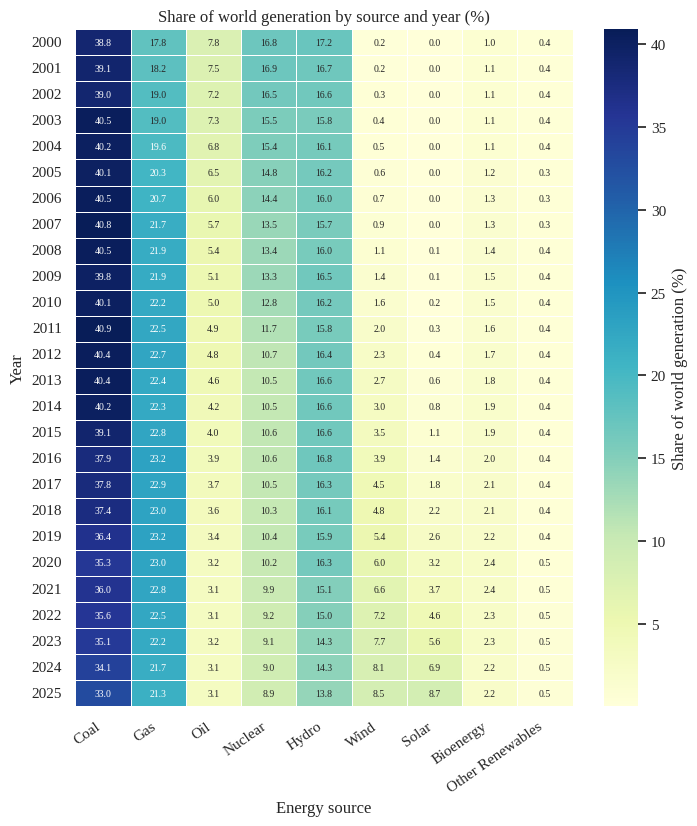

Largest share in 2000: Coal (38.8 %)
Largest share in 2025: Coal (33.0 %)
Fastest rising share : Solar (+8.7 pp)
Fastest falling share: Nuclear (-7.9 pp)


In [30]:
# (1) grouped bar plot: share of generation by source in selected years
sel = share.set_index('Year').loc[[2000, 2010, 2025], SOURCES].T
sel.index = [s.replace('_', ' ') for s in sel.index]
ax = sel.plot(kind='bar', figsize=(8.5, 4.4), width=0.75, color=['#95a5a6', '#5d8aa8', '#c0392b'])
ax.set_ylabel('Share of world generation (%)'); ax.set_xlabel('Energy source')
ax.set_title('Share of generation by source: 2000, 2010 and 2025')
plt.xticks(rotation=30, ha='right'); ax.legend(title='Year'); plt.tight_layout(); plt.show()

# (2) heat-map: regional generation mix in 2025 (% of each region's electricity)
reg_share = rw.div(rw.sum(axis=1), axis=0) * 100
reg_share.columns = [c.replace('_', ' ') for c in reg_share.columns]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
sns.heatmap(reg_share, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=.5, ax=ax,
            cbar_kws={'label': 'Share of regional generation (%)'}, annot_kws={'size': 9})
ax.set_title('Generation mix of each region, 2025'); ax.set_xlabel('Energy source'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

# (3) heat-map: share of each source in each year
hm = share.set_index('Year')[SOURCES]
hm.columns = [c.replace('_', ' ') for c in hm.columns]
fig, ax = plt.subplots(figsize=(7.2, 8.4))
sns.heatmap(hm, annot=True, fmt='.1f', cmap='YlGnBu', linewidths=.4, annot_kws={'size': 7},
            cbar_kws={'label': 'Share of world generation (%)'}, ax=ax)
ax.set_title('Share of world generation by source and year (%)')
ax.set_xlabel('Energy source'); ax.set_ylabel('Year')
plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()

print('Largest share in 2000: %s (%.1f %%)' % (hm.loc[2000].idxmax(), hm.loc[2000].max()))
print('Largest share in 2025: %s (%.1f %%)' % (hm.loc[2025].idxmax(), hm.loc[2025].max()))
diff = hm.loc[2025] - hm.loc[2000]
print('Fastest rising share : %s (%+.1f pp)' % (diff.idxmax(), diff.max()))
print('Fastest falling share: %s (%+.1f pp)' % (diff.idxmin(), diff.min()))